# Step 13: self-supervised 3D encoder + subtype-aware stacking (GPU T4, ~1-1.5 h)
Two ideas that use the data differently from every earlier step:

1. **Self-supervised pretraining (SimCLR) of a 3D CNN** on every cached BreastDCEDL patient of the train and val
   splits, **including the Duke patients without a pCR label** (no labels are used; the test split never is).
   All earlier image models started from natural-image weights and looked at 2D slices; with ~1,100 labels a 3D
   encoder cannot be learned from scratch with supervision, but the images themselves can teach it (two random
   augmentations of a tumour -> similar embeddings). More Duke images matter because every model so far is at chance
   on Duke. The MAMA-MIA challenge winner used 3D SimCLR on lesion-centred volumes. Evaluated with a linear probe
   against the **same architecture with random weights**, so any gain is due to the pretraining.
2. **Subtype-aware stacking**: level 1 = every image model's out-of-fold score (steps 11, 12, 13a; attach their
   notebook outputs), the step-9 kinetic score and the tumour volume from our cleaned mask; level 2 = a logistic
   regression on the clinical variables (age, menopause, race, HR, HER2) + volume + image scores, adding one input
   at a time, with subtype interactions and per-subtype models. This answers the main question of the project:
   **does the image add anything to the clinical data?**, on all ~1,100 train patients (OOF) and on val.

Kaggle setup: Accelerator **GPU T4 x2**, Internet **ON**.
**+ Add Input**:
- the caches (the best one attached per cohort is used and printed): **`mnj-cache2-ispy1/-ispy2/-duke`** (raw,
  step 2: nothing clipped) if you have them, else `mnj-cache-v2` or `mnj-cache-ispy1/-ispy2/-duke` (uint8, clipped:
  the code works, but the brightest enhancement is lost);
- the code: the **`mnj-code-vaib` Dataset, NEW version** (the zip made on 2026-11-04 or later has the steps 11-13
  code; the setup cell stops with a clear message if the attached code is older).

Run with `DEBUG = True` first (a few minutes, 40 patients per split) to check the notebook, then `DEBUG = False`
with **Save Version -> Save & Run All (Commit)**. Every step prints a timestamped `[...]` line. Results: Output tab,
`results/<PERSON>/<step>/`. Background and rationale: `docs/vaib/STEPS_11_13.md`.
For the full stack also attach **+ Add Input -> Your Work -> Notebooks -> your step-11 and step-12 notebooks**
(their `stack_inputs.csv` are found automatically). Without them, step 13 stacks what it computes itself.

In [1]:
# ==== PARAMETERS (edit these) ====
REPO = "AkulaReddy/MRI_chemo_response"
GIT_TAG = "vaib"           # branch (or tag) to clone
PERSON = ""               # optional: "A", "B" or "C" -> results/<PERSON>/ (empty -> results/vaib/)
STEP = "step13"
PREFER = "v2"
RUN_SSL = True
SSL_EPOCHS = 150             # SimCLR epochs (stops earlier when SSL_MAX_MINUTES is reached)
SSL_BATCH = 64
SSL_MAX_MINUTES = 150
USE_UNLABELED = True         # also pretrain on the Duke patients without a pCR label (train / val splits only)
REPEATS = 5                  # repeated 5-fold CV for the linear probe and the level-2 models (DEBUG uses 2)
JOBS = 4
STACK_INPUTS = []            # extra folders / files with stack_inputs.csv (attached step 11 / 12 outputs are found anyway)
EXTRA_PIP = []
TIME_BUDGET_H = 11.0
DEBUG = False                # True: 40 patients per split, 3 SimCLR epochs, 2 CV repeats
PUSH_RESULTS = False
NOTEBOOK_NAME = "step13"

In [2]:
# ==== SETUP (do not edit): get the repo code, install requirements ====
import base64, glob, json, os, shutil, subprocess, sys, zipfile
if PERSON not in ("A", "B", "C"):           # only names the results folder
    PERSON = "vaib"
    print('PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)')
NEEDS = "src/vitonly/rcv.py"               # the steps 11-13 code (in the mnj-code-vaib zip made on 2026-11-04 or later)
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as e:
    print("no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached):",
          type(e).__name__)

def git(*args, cwd="/tmp/repo"):
    """git with the token as a one-off header (never stored in .git/config or the output)."""
    if not _tok:
        raise RuntimeError("no GITHUB_TOKEN secret: git push/pull is not available")
    hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={hdr}", *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(_tok, "***")
    if r.returncode:
        raise RuntimeError(f"git {args[0]} failed:\n{out}")
    return out

def _find_code():
    """An attached code Dataset that already has the steps 11-13 code (an unpacked folder or the uploaded zip)."""
    hits = [h for d in range(1, 8) for h in glob.glob("/kaggle/input/" + "*/" * d + NEEDS)]
    if not hits:
        for z in [z for d in range(1, 6) for z in glob.glob("/kaggle/input/" + "*/" * d + "mnj-code-vaib*.zip")]:
            zipfile.ZipFile(z).extractall("/tmp/code_zip")
        hits = glob.glob("/tmp/code_zip/**/" + NEEDS, recursive=True)
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

shutil.rmtree("/tmp/repo", ignore_errors=True)
code_root = _find_code()
if code_root:                               # 1) the attached code Dataset with the new code wins
    shutil.copytree(code_root, "/tmp/repo")
    print("code: attached Dataset", code_root)
elif _tok:                                  # 2) or clone the branch from GitHub
    git("clone", "--quiet", "--depth", "1", "--branch", GIT_TAG, f"https://github.com/{REPO}.git", "/tmp/repo", cwd="/tmp")
    print("code: GitHub", REPO, GIT_TAG, git("log", "-1", "--format=%h %s"))
    if not os.path.exists(f"/tmp/repo/{NEEDS}"):
        raise SystemExit(f"branch {GIT_TAG} has no steps 11-13 code ({NEEDS}). Attach the NEW mnj-code-vaib zip "
                         "(+ Add Input -> Your Datasets -> mnj-code-vaib, latest version), or set GIT_TAG to a branch with it.")
else:
    print("attached inputs:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") <= 5:
            print("  ", root, dirs[:6], files[:4])
        else:
            dirs[:] = []
    raise SystemExit(
        "\nThe notebook can't find the steps 11-13 code. Upload the new mnj-code-vaib.zip as a NEW VERSION of the\n"
        "mnj-code-vaib Dataset, then + Add Input -> Your Datasets -> mnj-code-vaib (latest version) and Run All again.")
os.chdir("/tmp/repo")
sys.path.insert(0, "/tmp/repo")         # so `from src...` works in this kernel
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-kaggle.txt"], check=True)
for pkg in EXTRA_PIP:                   # optional extras: a failed install is reported, never fatal
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    print(f"pip install {pkg}:", "ok" if r.returncode == 0 else "FAILED (the step that needs it is skipped)\n" + r.stderr[-500:])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)
no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached): BackendError
code: attached Dataset /kaggle/input/datasets/a15chvaibhav/mnj-code-vaib/MRI_chemo_response
torch 2.11.0+cu130 | GPU: Tesla T4


In [3]:
# ==== HELPERS (do not edit): training runs, prediction files, comparisons ====
import glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import evaluation as ev, stats
from src.train import find_caches
from src.data.metadata import patient_table
COH = ["ispy1", "ispy2", "duke"]
OUT = f"/kaggle/working/results/{PERSON}/{STEP}"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
RUNS_JSON = {}
pd.set_option("display.width", 250, "display.max_columns", 40)

def budget_left():
    return TIME_BUDGET_H - (time.time() - T0) / 3600

def say(msg):
    """Timestamped progress line (elapsed and remaining budget), flushed so it shows in the Kaggle log at once."""
    el = (time.time() - T0) / 3600
    print(f"[{time.strftime('%H:%M:%S')} | {el:.2f} h elapsed, {budget_left():.2f} h left] {msg}", flush=True)

def run_cmd(cmd):
    """Run a training subprocess and stream its output line by line into this notebook (subprocess.run alone
    shows nothing until it ends, and the child's stdout is block-buffered without PYTHONUNBUFFERED)."""
    print("\n" + " ".join(cmd), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait():
        raise subprocess.CalledProcessError(p.returncode, cmd)
    say(f"finished in {(time.time() - t) / 60:.1f} min")

def check_caches(version):
    caches = find_caches(["/kaggle/input", "/kaggle/working"])
    info = {c: json.load(open(f"{d}/cache_meta.json")).get("builder_version", 1) for c, d in caches.items()}
    print("caches:", {c: f"builder v{v}: {caches[c]}" for c, v in info.items()})
    if version is not None:
        bad = {c: v for c, v in info.items() if v != version}
        assert not bad and len(info) == 3, (f"need cache builder v{version} for all 3 cohorts (attach mnj-cache-v2); "
                                            f"found {info}")
    return caches

def _copy(d, label):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    for f in ("val_preds.csv", "metrics.json", "log.csv", "config_resolved.yaml", "export_preds.csv",
              "train_preds.csv", "encoder.json"):
        if os.path.exists(f"{d}/{f}"):
            shutil.copy(f"{d}/{f}", f"{OUT}/{label}/{f}")

def train(config, seed, sets=(), label=None, cohorts=None):
    """One src.train run (B3 / F2 ...) -> (run_dir, metrics). Its small files are copied to OUT/<label>/."""
    cmd = [sys.executable, "-m", "src.train", "--config", config, "--seed", str(seed), "--out", "/kaggle/working/runs"]
    if CACHE_VERSION is not None: cmd += ["--cache-version", str(CACHE_VERSION)]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d, json.load(open(f"{d}/metrics.json"))

def finetune(config, seed, sets=(), label=None, cohorts=None):
    """One src.vitonly.finetune run (our pipeline: ViT-only vo_base / fusion vo_fusion) -> run_dir."""
    cmd = [sys.executable, "-m", "src.vitonly.finetune", "--config", config, "--seed", str(seed),
           "--cache-root", "/kaggle/input", "/kaggle/working", "--out", "/kaggle/working/runs"]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d

def note_runs(key, dirs):
    """label -> run folder names, in OUT/runs.json: step 8 uses it to find the checkpoints."""
    RUNS_JSON[key] = [os.path.basename(d) for d in dirs]
    json.dump(RUNS_JSON, open(f"{OUT}/runs.json", "w"), indent=1)

def preds_of(dirs):
    fr = [ev.load_preds(f"{d}/val_preds.csv") for d in dirs]
    return fr[0] if len(fr) == 1 else ev.ensemble(fr)

def save_preds(label, df):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    df.to_csv(f"{OUT}/{label}/val_preds.csv", index=False)
    return df

def repo_preds(pattern):
    hits = sorted(glob.glob(f"results/*/{pattern}/val_preds.csv"))
    return preds_of([os.path.dirname(h) for h in hits]) if hits else None

def train_auc(d):
    """AUC on the training patients from export_preds.csv (B3 exports after training): the overfitting gap."""
    f = f"{d}/export_preds.csv"
    if not os.path.exists(f): return np.nan
    e = pd.read_csv(f); e = e[e.split == "train"]
    return stats.auc(e.label, e.prob)

def vo_train_auc(d):
    """Training-set AUC of a src.vitonly run (metrics.json): the overfitting gap."""
    return json.load(open(f"{d}/metrics.json"))["val"].get("train_auc", np.nan)

def compare(preds, ref):
    """One row per model on the patients all models share: AUC (DeLong CI), AUPRC, Brier, ECE, the 90%-spec
    operating point (threshold chosen on these same val patients: optimistic), and the paired DeLong test
    and paired bootstrap of the AUC difference vs `ref`."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    rows = []
    for k, d in preds.items():
        r = {"model": k, **ev.summary_row(d.label, d.prob)}
        if k != ref and ref in preds:
            y = preds[ref].label
            dl = ev.delong(y, preds[ref].prob, d.prob)
            pb = stats.paired_bootstrap_auc_diff(y, preds[ref].prob, d.prob)
            r.update(diff_vs_ref=dl["diff"], delong_ci_lo=dl["ci"][0], delong_ci_hi=dl["ci"][1], delong_p=dl["p"],
                     boot_p=pb["p"])
        rows.append(r)
    cols = ["model", "n", "pcr", "auc", "ci_lo", "ci_hi", "auprc", "brier", "ece", "sens@90spec", "ppv@90spec",
            "npv@90spec", "diff_vs_ref", "delong_ci_lo", "delong_ci_hi", "delong_p", "boot_p"]
    t = pd.DataFrame(rows)
    return t[[c for c in cols if c in t]]

def subtype_wide(preds, by="subtype"):
    """AUC (95% CI) per subtype (or cohort) for every model, all on the same patients; n / pCR+ per group."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    tabs = {k: ev.subgroup_table(d, by).set_index(by) for k, d in preds.items()}
    first = next(iter(tabs.values()))
    out = pd.DataFrame({"n": first.n.astype(int), "pCR+": first.pcr.astype(int)})
    for k, t in tabs.items():
        out[k] = [f"{a:.3f} ({lo:.2f}-{hi:.2f})" if a == a else "n/a (one class)"
                  for a, lo, hi in zip(t.auc, t.ci_lo, t.ci_hi)]
    return out

B1_VAL = repo_preds("b1_lr_s0_*")                       # clinical + tumour size, logistic regression (val 0.653)
B0_VAL = repo_preds("b0_lr_s0_*")                       # clinical only (val 0.639)
AKULA_B3_V2 = repo_preds("b3_vit_s0_1019-0302_*")       # Akula's B3 on cache v2 (val 0.559)
B3_V1 = repo_preds("b3_vit_s0_1009-1616_*")             # B3 on the old cache (val 0.530)
F2_V1 = repo_preds("f2_attn_s0_1009-1605_*")            # fusion on the old cache (val 0.690)
print("reference predictions from the repo:", {k: v is not None for k, v in
      dict(B1=B1_VAL, B0=B0_VAL, B3_v2_Akula=AKULA_B3_V2, B3_v1=B3_V1, F2_v1=F2_V1).items()})

reference predictions from the repo: {'B1': True, 'B0': True, 'B3_v2_Akula': True, 'B3_v1': True, 'F2_v1': True}


In [4]:
# ==== which cache is used for each cohort ====
from src.vitonly.slabs import find_caches as vo_find_caches, cache_label
VO_CACHES = vo_find_caches(["/kaggle/input", "/kaggle/working"], PREFER)
say(f"caches found: {len(VO_CACHES)} cohorts")
for c in COH:
    print(f"  {c:6s}", f"{cache_label(VO_CACHES[c])}  {VO_CACHES[c]}" if c in VO_CACHES else "MISSING -> left out", flush=True)
if not VO_CACHES:
    raise SystemExit("no cache attached: + Add Input -> mnj-cache2-* / mnj-cache-v2 / mnj-cache-*")
if any(cache_label(d).startswith("v1") for d in VO_CACHES.values()):
    print("NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. "
          "Raw mnj-cache2-* caches (step 2) are exact.", flush=True)

[10:16:52 | 0.00 h elapsed, 11.00 h left] caches found: 3 cohorts
  ispy1  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
  ispy2  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
  duke   v1 uint8 builder 1  /kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke
NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. Raw mnj-cache2-* caches (step 2) are exact.


## 1. SimCLR pretraining of the 3D encoder, then the linear probe (GPU, ~45-60 min)

[10:16:52 | 0.00 h elapsed, 11.00 h left] 1. SimCLR starts (a line every 5 epochs), then the linear probe

/usr/bin/python3 -m src.vitonly.ssl3d --out /kaggle/working/results/vaib/step13/ssl3d --epochs 150 --batch 64 --max-minutes 150 --repeats 5 --jobs 4 --prefer v2 --cache-root /kaggle/input /kaggle/working
[ssl3d 10:16:55 +0.0 min] step 1/4: patients and volumes | device cuda:0 | args {'out': '/kaggle/working/results/vaib/step13/ssl3d', 'epochs': 150, 'batch': 64, 'lr': 0.001, 'width': 32, 'max_minutes': 150.0, 'no_unlabeled': False, 'repeats': 5, 'folds': 5, 'jobs': 4, 'workers': 4, 'cohorts': ['ispy1', 'ispy2', 'duke'], 'cache_root': ['/kaggle/input', '/kaggle/working'], 'prefer': 'v2', 'limit': 0, 'cpu': False}
[data] 1 of 1099 patients have no cache entry, dropped (first: ['Breast_MRI_577'])
[data] 2 of 1532 patients have no cache entry, dropped (first: ['Breast_MRI_250', 'Breast_MRI_577'])
[ssl3d 10:16:55 +0.0 min]   cache ispy1: v1 uint8 builder 1
[ssl3d 10:16:55 +0.0 min]   c

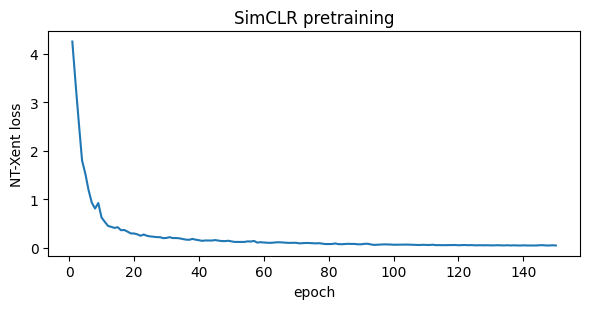

           set        mode  combat  cv_auc  oof_auc  oof_within_subtype  val_auc  val_within_subtype  oof_vs_lookup  oof_vs_lookup_p
         ssl3d    +subtype    True   0.687    0.691               0.586    0.674               0.589          0.064            0.000
         ssl3d    +subtype   False   0.685    0.688               0.577    0.659               0.579          0.061            0.000
         ssl3d per_subtype    True   0.674    0.681               0.561    0.656               0.495          0.054            0.000
         ssl3d per_subtype   False   0.672    0.679               0.553    0.656               0.507          0.052            0.000
      random3d    +subtype    True   0.664    0.667               0.542    0.611               0.484          0.040            0.004
      random3d    +subtype   False   0.662    0.665               0.530    0.607               0.449          0.037            0.010
subtype_lookup      lookup   False   0.658    0.627               0.3

In [5]:
SSL = f"{OUT}/ssl3d"
if RUN_SSL:
    cmd = [sys.executable, "-m", "src.vitonly.ssl3d", "--out", SSL, "--epochs", str(3 if DEBUG else SSL_EPOCHS),
           "--batch", str(SSL_BATCH), "--max-minutes", str(SSL_MAX_MINUTES), "--repeats", str(2 if DEBUG else REPEATS),
           "--jobs", str(JOBS), "--prefer", PREFER, "--cache-root", "/kaggle/input", "/kaggle/working"]
    if not USE_UNLABELED: cmd.append("--no-unlabeled")
    if DEBUG: cmd += ["--limit", "40"]
    say("1. SimCLR starts (a line every 5 epochs), then the linear probe")
    run_cmd(cmd)
    SRES = pd.read_csv(f"{SSL}/results.csv")
    hist = pd.read_csv(f"{SSL}/ssl_loss.csv")
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(hist.epoch + 1, hist.loss); ax.set_xlabel("epoch"); ax.set_ylabel("NT-Xent loss"); ax.set_title("SimCLR pretraining")
    plt.tight_layout(); plt.savefig(f"{OUT}/ssl_loss.png", dpi=120); plt.show()
    cols = ["set", "mode", "combat", "cv_auc", "oof_auc", "oof_within_subtype", "val_auc", "val_within_subtype",
            "oof_vs_lookup", "oof_vs_lookup_p"]
    print(SRES[[c for c in cols if c in SRES]].round(3).to_string(index=False))
    print(pd.read_csv(f"{SSL}/comparisons.csv")[["comparison", "oof_auc_a", "oof_auc_b", "oof_diff", "oof_p", "val_diff", "val_p"]]
          .round(3).to_string(index=False))
else:
    say("1. skipped (RUN_SSL = False)")

## 2. Subtype-aware stacking: does the image add to the clinical data?

In [6]:
found = sorted(set(glob.glob("/kaggle/input/**/stack_inputs.csv", recursive=True)))   # attached step 11 / 12 outputs
inputs = found + list(STACK_INPUTS) + ([SSL] if RUN_SSL and os.path.exists(f"{SSL}/stack_inputs.csv") else [])
say("2. level-1 inputs: " + (", ".join(inputs) if inputs else "none attached (stacking uses clinical + volume + kinetic only)"))
ST = f"{OUT}/stacking"
cmd = [sys.executable, "-m", "src.vitonly.stacking", "--out", ST, "--repeats", str(2 if DEBUG else REPEATS),
       "--jobs", str(JOBS), "--prefer", PREFER, "--cache-root", "/kaggle/input", "/kaggle/working"]
if inputs: cmd += ["--inputs", *inputs]
if DEBUG: cmd += ["--limit", "40"]
run_cmd(cmd)
RES = pd.read_csv(f"{ST}/results.csv")
CMPS = pd.read_csv(f"{ST}/comparisons.csv")
VAL = pd.read_csv(f"{ST}/val_preds.csv", dtype={"pid": str})
say(f"2. done: {len(RES)} level-2 models")

[11:35:06 | 1.30 h elapsed, 9.70 h left] 2. level-1 inputs: /kaggle/working/results/vaib/step13/ssl3d

/usr/bin/python3 -m src.vitonly.stacking --out /kaggle/working/results/vaib/step13/stacking --repeats 5 --jobs 4 --prefer v2 --cache-root /kaggle/input /kaggle/working --inputs /kaggle/working/results/vaib/step13/ssl3d
[stacking 11:35:09 +0.0 min] step 1/4: patients, clinical variables, tumour volume, kinetic score | args {'inputs': ['/kaggle/working/results/vaib/step13/ssl3d'], 'out': '/kaggle/working/results/vaib/step13/stacking', 'repeats': 5, 'folds': 5, 'jobs': 4, 'cohorts': ['ispy1', 'ispy2', 'duke'], 'cache_root': ['/kaggle/input', '/kaggle/working'], 'prefer': 'v2', 'limit': 0}
[data] 1 of 1099 patients have no cache entry, dropped (first: ['Breast_MRI_577'])
[stacking 11:36:46 +1.6 min]   train 1098 | val 177 | clinical columns 10 | tumour volume missing for 0
[stacking 11:36:53 +1.7 min]   kinetic16 level-1 score: oof 0.528 | val 0.607
[stacking 11:36:53 +1.7 min] step 2/4: 

## 3. Summary

                                 model inputs  cv_auc  cv_auc_sd  oof_auc  oof_within_subtype  oof_within_cohort  val_auc  val_ci_lo  val_ci_hi  val_within_subtype  oof_vs_lookup  oof_vs_lookup_p
                        subtype_lookup      -   0.658      0.031    0.627               0.394              0.643    0.662      0.575      0.740               0.500            NaN              NaN
                              clinical     10   0.691      0.027    0.688               0.554              0.723    0.649      0.555      0.739               0.536          0.061              0.0
                       clinical+volume     11   0.695      0.028    0.696               0.582              0.728    0.656      0.569      0.742               0.556          0.068              0.0
                 clinical+volume+kin16     12   0.695      0.028    0.694               0.577              0.727    0.653      0.563      0.739               0.544          0.067              0.0
             clinica

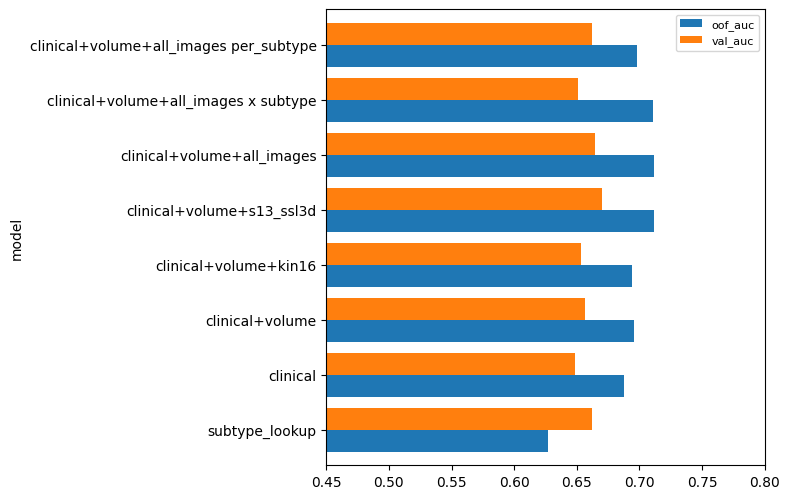


Paired comparisons (b - a):
                                               comparison  oof_auc_a  oof_auc_b  oof_diff  oof_p  val_auc_a  val_auc_b  val_diff  val_p
                               subtype lookup -> clinical      0.627      0.688     0.061  0.000      0.662      0.649    -0.013  0.680
                                     clinical -> + volume      0.688      0.696     0.008  0.170      0.649      0.656     0.008  0.640
                 clinical+volume -> clinical+volume+kin16      0.696      0.694    -0.002  0.202      0.656      0.653    -0.003  0.424
             clinical+volume -> clinical+volume+s13_ssl3d      0.696      0.712     0.016  0.028      0.656      0.670     0.014  0.164
            clinical+volume -> clinical+volume+all_images      0.696      0.712     0.017  0.022      0.656      0.664     0.008  0.472
  clinical+volume -> clinical+volume+all_images x subtype      0.696      0.711     0.015  0.048      0.656      0.651    -0.006  0.630
clinical+volume -> 

In [7]:
cols = ["model", "inputs", "cv_auc", "cv_auc_sd", "oof_auc", "oof_within_subtype", "oof_within_cohort", "val_auc",
        "val_ci_lo", "val_ci_hi", "val_within_subtype", "oof_vs_lookup", "oof_vs_lookup_p"]
print(RES[[c for c in cols if c in RES]].round(3).to_string(index=False))
r = RES.set_index("model")[["oof_auc", "val_auc"]]
ax = r.plot.barh(figsize=(8, 0.45 * len(r) + 1.5), width=0.8)
ax.set_xlim(0.45, max(0.8, float(np.nanmax(r.values)) + 0.02)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/stacking_auc.png", dpi=120); plt.show()
print("\nPaired comparisons (b - a):")
print(CMPS[["comparison", "oof_auc_a", "oof_auc_b", "oof_diff", "oof_p", "val_auc_a", "val_auc_b", "val_diff", "val_p"]]
      .round(3).to_string(index=False))
ok = RES[RES.model != "subtype_lookup"].sort_values("cv_auc", ascending=False)
BEST = {"clinical": "clinical", **{f"best stack {i + 1}: {m}": m for i, m in enumerate(ok.model.head(2)) if m != "clinical"}}
say("best level-2 models by CV: " + ", ".join(ok.model.head(3)))

# ---- the best configurations against the team's models on val (paired DeLong vs the subtype lookup) ----
def as_preds(frame, col):
    return frame[["pid", "cohort", "label"]].assign(prob=frame[col].values)
preds = {"B1 LR (clinical + size)": B1_VAL, "subtype lookup": as_preds(VAL, "subtype_lookup"),
         "F2 fusion v1 (old cache)": F2_V1}
preds.update({f"{STEP}: {name}": as_preds(VAL, col) for name, col in BEST.items() if col in VAL})
CMP = compare(preds, "subtype lookup")
print(CMP.round(3).to_string(index=False))
CMP.to_csv(f"{OUT}/comparison_vs_team.csv", index=False)
ours = {k: v for k, v in preds.items() if k.startswith(STEP)}
if ours:
    print("\nper subtype (val):"); print(subtype_wide(ours).to_string())
    print("\nper cohort (val):"); print(subtype_wide(ours, by="cohort").to_string())

## 4. Results file

In [8]:
from src.vitonly.rcv import md_table
parts = []
if RUN_SSL and os.path.exists(f"{SSL}/RESULTS.md"):
    parts.append(open(f"{SSL}/RESULTS.md").read())
parts.append(open(f"{ST}/RESULTS.md").read())
parts.append("## Best models vs the team's models (val, paired DeLong vs the subtype lookup)\n\n" + md_table(CMP) + "\n")
open(f"{OUT}/RESULTS_step13.md", "w").write("\n".join(parts))
say(f"wrote {OUT}/RESULTS_step13.md -- download it from the Output tab (or PUSH_RESULTS)")

[11:39:00 | 1.37 h elapsed, 9.63 h left] wrote /kaggle/working/results/vaib/step13/RESULTS_step13.md -- download it from the Output tab (or PUSH_RESULTS)


In [9]:
# ==== PUSH the small result files to the vaib branch (results/<PERSON>/...) ====
if PUSH_RESULTS and not _tok:
    print("PUSH_RESULTS needs the GITHUB_TOKEN secret; download results/ from the Output tab instead")
elif PUSH_RESULTS and not DEBUG:
    git("config", "user.name", f"Person {PERSON} (Kaggle)")
    git("config", "user.email", "kaggle@users.noreply.github.com")
    for attempt in range(3):
        git("fetch", "--quiet", "--depth", "1", "origin", f"+refs/heads/{GIT_TAG}:refs/remotes/origin/{GIT_TAG}")
        git("checkout", "--quiet", "-f", "-B", GIT_TAG, f"origin/{GIT_TAG}")
        shutil.copytree(f"/kaggle/working/results/{PERSON}", f"results/{PERSON}", dirs_exist_ok=True)
        git("add", f"results/{PERSON}")
        print(git("commit", "-m", f"results: {PERSON} {NOTEBOOK_NAME} ({GIT_TAG})"))
        try:
            git("push", "--quiet", "origin", GIT_TAG); print("pushed to", GIT_TAG); break
        except RuntimeError as e:
            print(f"push attempt {attempt + 1} failed:", e)
    else:
        print("NOT pushed: download results/ from the Output tab")